# 06 · Badminton — modele, błędy i liczba uderzeń
**Dane rzeczywiste:** cztery serie central/off-center z jednej rakiety, 46 automatycznych kandydatów.
To demonstracja narzędzi, nie pomiar skuteczności wykrywania wad ceramiki.

Wybierz kernel `.venv` / Ping Lab i **Run All**. Ten notebook działa samodzielnie;
nie musisz wcześniej uruchamiać pozostałych. Granice serii i zapowiedzi pochodzą
z `data/raw/badminton/session.json`. `project.json` pozostaje konfiguracją oryginalnych notebooków.
Nowe wyniki trafiają do osobnego katalogu; nagranie źródłowe pozostaje bez zmian.


In [1]:
NOTEBOOK = '06_porownanie_metod'
from pathlib import Path
import sys, json, hashlib, io, base64
from datetime import datetime
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pinglab').is_dir()), None)
assert ROOT is not None, 'Otwórz notebook z folderu projektu ceramic-ping-lab.'
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'scripts'))
%matplotlib inline
cfg = json.loads((ROOT/'data/raw/badminton/session.json').read_text())
SOURCE = ROOT/'data/raw/badminton'/cfg['audio']
assert SOURCE.is_file(), 'Brak nagrania badminton: nie przełączamy się automatycznie na demo.'
OUT = ROOT/'reports/runs/badminton-notebooks'/NOTEBOOK/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Audio, HTML, Markdown
from pinglab.audio import load_audio, Config
from pinglab.recorder import segment_ringdown, ringdown_plot
from pinglab.features import extract_features, feature_columns, decay_curve
from pinglab.learning import make_classifier
from pinglab.series import evaluate_series, paired_folds
from pinglab.embeddings import ASTEncoder
from pinglab.robustness import mix_noise

RUN_AST = True
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
colors = {'central':'#137f83', 'offcenter':'#c56838'}
r = load_audio(SOURCE, Config(sr=48000, max_seconds=180))
print('Plik:', SOURCE.name, '| SHA256:', hashlib.sha256(SOURCE.read_bytes()).hexdigest())
display(pd.DataFrame([r.qc]).drop(columns=['warnings']))
print('Uwagi QC:', r.qc['warnings'] or 'brak')

Plik: session.wav | SHA256: afc2d308b32b80ead3f80f795707a2059d2e359a33a2d6c20470464d41df7f07


,duration_s,native_sr,channels,selected_channel,peak_dbfs,rms_dbfs,clipping_fraction,dc_offset
0,88.99771,44100,1,0,-17.976912,-45.595115,0.0,8.182004e-09


Uwagi QC: ['Pasmo źródłowe kończy się przy 22050 Hz; resampling go nie odzyska']


## Przygotowanie uderzeń
Ten sam detektor i okna: 25 ms przed + 350 ms po początku, skrócone przed kolejnym zdarzeniem. Etykieta pochodzi z serii. Zdarzenie około 77 s pozostaje niepewne.

In [2]:
rows=[]; clips={}; series_traces={}
for s in cfg['series']:
 z=r.y[int(s['start_s']*r.sr):int(s['end_s']*r.sr)]
 tab,t,db=segment_ringdown(z,r.sr,**cfg['detector'])
 series_traces[s['series_id']]=(z,tab,t,db)
 interactive=ringdown_plot(z,r.sr,tab,t,db)
 interactive.write_html(OUT/(s['series_id']+'_segmentacja.html'),include_plotlyjs=True)
 for k,row in enumerate(tab.itertuples()):
  onset=float(row.onset_s);absolute=s['start_s']+onset
  a=max(0,onset-cfg['pre_s'])
  nxt=float(tab.iloc[k+1].onset_s) if k+1<len(tab) else len(z)/r.sr
  b=min(onset+cfg['feature_tail_s'],nxt-.015,len(z)/r.sr)
  clip=z[int(a*r.sr):int(b*r.sr)]
  eid=f"{s['series_id']}_{k+1:02d}"
  clips[eid]=clip
  uncertain=any(abs(absolute-v)<.05 for v in cfg['uncertain_onsets_s'])
  rows.append(dict(event_id=eid,series_id=s['series_id'],round=s['round'],label=s['label'],
   onset_s=absolute,offset_s=onset-a,window_s=len(clip)/r.sr,
   ringdown_s=row.duration_s,ringdown_status=row.status,uncertain=uncertain,
   peak_dbfs=20*np.log10(max(abs(clip).max(),1e-12)),
   **extract_features(clip,r.sr,onset-a,cfg['fmax'])))
events=pd.DataFrame(rows)
events.to_csv(OUT/'features.csv',index=False)
display(events.groupby(['series_id','label'],sort=False).agg(uderzenia=('event_id','size'),
 szczyt_mediana_dbfs=('peak_dbfs','median'),niepewne=('uncertain','sum')))
display(events[['event_id','onset_s','ringdown_s','ringdown_status','uncertain']])
assert all(not (a<=v<=b) for v in events.onset_s for a,b in cfg['speech_excluded_s'])
assert events.window_s.min()>.05

,,uderzenia,szczyt_mediana_dbfs,niepewne
series_id,label,,,
central_1,central,14,-26.799461,0
offcenter_1,offcenter,12,-34.025085,0
central_2,central,10,-31.644835,0
offcenter_2,offcenter,10,-31.444176,1


,event_id,onset_s,ringdown_s,ringdown_status,uncertain
0,central_1_01,8.525,0.070,zanik zaobserwowany,False
1,central_1_02,9.670,0.100,zanik zaobserwowany,False
2,central_1_03,10.860,0.140,zanik zaobserwowany,False
3,central_1_04,11.885,0.315,zanik zaobserwowany,False
4,central_1_05,12.945,0.170,zanik zaobserwowany,False
5,central_1_06,14.110,1.055,kolejne uderzenie przed zanikiem,False
6,central_1_07,15.165,0.570,zanik zaobserwowany,False
7,central_1_08,16.300,0.215,zanik zaobserwowany,False
8,central_1_09,17.385,0.120,zanik zaobserwowany,False
9,central_1_10,18.610,0.115,zanik zaobserwowany,False


## 5. Klasyfikacja i odległość od centralnych wzorców
Dwie próby: uczymy na seriach 1–2 i sprawdzamy 3–4, potem odwrotnie. Skalowanie i model uczą się tylko na części treningowej. Używamy ustalonej regresji logistycznej (`C=0.1`), bez poszukiwania najlepszego parametru.

Odległość pyta: „jak daleko ten dźwięk leży od centralnych uderzeń treningowych?”. Próg pochodzi wyłącznie z odległości między wzorcami treningowymi, ale nie jest skalibrowany. AUC ocenia kolejność wyników bez progu; balanced accuracy uśrednia trafność obu klas.

**Dwie rundy jednej sesji nie wystarczają do wiarygodnej oceny generalizacji.** Uderzenia są skorelowane; nie liczymy przedziałów ufności tak, jakby były niezależnymi obiektami. Porównanie wielu metod jest eksploracyjne.


,fold,train_series,test_series
0,1,"[central_2, offcenter_2]","[central_1, offcenter_1]"
1,2,"[central_1, offcenter_1]","[central_2, offcenter_2]"


,family,method,test_round,n_test,balanced_accuracy,auc,central_recall,offcenter_recall
0,loudness,logistic,1,26,0.161,0.048,0.071,0.250
1,loudness,logistic,2,20,0.400,0.470,0.200,0.600
2,resonance,logistic,1,26,0.286,0.185,0.071,0.500
3,resonance,logistic,2,20,0.450,0.470,0.400,0.500
4,resonance,distance,1,26,0.500,0.804,1.000,0.000
5,resonance,distance,2,20,0.450,0.630,0.900,0.000
6,physics,logistic,1,26,0.482,0.470,0.214,0.750
7,physics,logistic,2,20,0.550,0.570,0.400,0.700
8,physics,distance,1,26,0.512,0.583,0.857,0.167
9,physics,distance,2,20,0.550,0.690,0.800,0.300


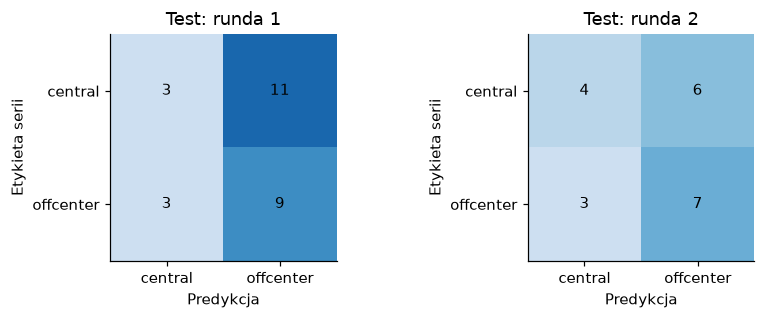

,event_id,series_id,label,fold,family,method,score,threshold,prediction,onset_s,uncertain
0,central_1_01,central_1,central,1,physics,logistic,0.565443,0.5,offcenter,8.525,False
1,central_1_02,central_1,central,1,physics,logistic,0.637992,0.5,offcenter,9.670,False
2,central_1_03,central_1,central,1,physics,logistic,0.512763,0.5,offcenter,10.860,False
3,central_1_05,central_1,central,1,physics,logistic,0.642296,0.5,offcenter,12.945,False
4,central_1_06,central_1,central,1,physics,logistic,0.624368,0.5,offcenter,14.110,False
5,central_1_07,central_1,central,1,physics,logistic,0.580101,0.5,offcenter,15.165,False
6,central_1_08,central_1,central,1,physics,logistic,0.572858,0.5,offcenter,16.300,False
7,central_1_09,central_1,central,1,physics,logistic,0.612724,0.5,offcenter,17.385,False
8,central_1_12,central_1,central,1,physics,logistic,0.714799,0.5,offcenter,21.020,False
9,central_1_13,central_1,central,1,physics,logistic,0.606400,0.5,offcenter,22.190,False


In [3]:
metrics=[];predictions=[]
for family in ['loudness','resonance','physics','mfcc','mel']:
 for method in (['logistic'] if family=='loudness' else ['logistic','distance']):
  m,p,audit=evaluate_series(events,family,method)
  metrics.append(m);predictions.append(p)
(OUT/'fold_audit.json').write_text(json.dumps(audit,indent=2))
display(pd.DataFrame(audit))
metrics=pd.concat(metrics,ignore_index=True);predictions=pd.concat(predictions,ignore_index=True)
display(metrics[['family','method','test_round','n_test','balanced_accuracy','auc','central_recall','offcenter_recall']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,row in zip(axes,metrics.query("family=='physics' and method=='logistic'").itertuples()):
 cm=np.array(row.confusion_matrix);ax.imshow(cm,cmap='Blues',vmin=0,vmax=14)
 for i in range(2):
  for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
 ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['central','offcenter'],yticklabels=['central','offcenter'],xlabel='Predykcja',ylabel='Etykieta serii',title=f'Test: runda {row.test_round}')
plt.tight_layout();plt.show()
errors=predictions.query("family=='physics' and method=='logistic' and label!=prediction")
display(errors.merge(events[['event_id','onset_s','uncertain']],on='event_id'))

## Opcjonalny AST
Lokalne wagi; RUN_AST można wyłączyć w pierwszej komórce.

In [4]:
if RUN_AST:
 encoder=ASTEncoder(ROOT/'models/ast',offline=True)
 cache=ROOT/'data/cache/badminton_ast';cache.mkdir(parents=True,exist_ok=True)
 vectors=[]
 for row in events.itertuples():
  signal=clips[row.event_id]
  key=hashlib.sha256(signal.tobytes()+str(r.sr).encode()+encoder.revision.encode()).hexdigest()
  target=cache/(key+'.npy')
  if target.exists():v=np.load(target,allow_pickle=False)
  else:v=encoder.encode(signal,r.sr);np.save(target,v)
  assert v.shape==(768,) and np.isfinite(v).all()
  vectors.append(v)
 ast= pd.concat([events.reset_index(drop=True),pd.DataFrame(vectors,columns=[f'ast_{i:03d}' for i in range(768)])],axis=1)
 m,p,_=evaluate_series(ast,'ast','logistic')
 metrics=pd.concat([metrics,m],ignore_index=True);predictions=pd.concat([predictions,p],ignore_index=True)
 display(m[['family','test_round','balanced_accuracy','auc','central_recall','offcenter_recall']].round(3))
 print('AST:',encoder.revision,'| embedding 768 | bez dostrajania wag')
else: print('AST pominięty ustawieniem RUN_AST=False')

,family,test_round,balanced_accuracy,auc,central_recall,offcenter_recall
0,ast,1,0.673,0.685,0.929,0.417
1,ast,2,0.650,0.720,0.800,0.500


AST: f826b80d28226b62986cc218e5cec390b1096902 | embedding 768 | bez dostrajania wag


## 8. Czy kilka uderzeń daje stabilniejszy wynik?
Dla ustalonego modelu fizycznego liczymy odsetek poprawnych decyzji opartych na medianie wyników 1, 3 lub 5 kolejnych uderzeń tej samej odłożonej serii. Okna zachodzą na siebie — to ilustracja stabilności, nie nowe niezależne testy.


In [5]:
base=predictions.query("family=='physics' and method=='logistic'")
taps=[]
for sid,g in base.groupby('series_id',sort=False):
 score=g.score.to_numpy(); truth=g.label.iloc[0]=='offcenter'
 for n in [1,3,5]:
  decisions=[np.median(score[i:i+n])>=.5 for i in range(len(score)-n+1)]
  taps.append(dict(series_id=sid,n_taps=n,n_windows=len(decisions),fraction_correct=np.mean(np.array(decisions)==truth)))
display(pd.DataFrame(taps).pivot(index='series_id',columns='n_taps',values='fraction_correct').round(3))
pd.DataFrame(taps).to_csv(OUT/'multiple_hits.csv',index=False)

n_taps,1,3,5
series_id,,,
central_1,0.214,0.167,0.0
central_2,0.400,0.375,0.5
offcenter_1,0.750,0.800,1.0
offcenter_2,0.700,0.750,1.0


## 10. Porównanie modeli — wyniki na odłożonych rundach
**Accuracy:** odsetek wszystkich poprawnych decyzji. **Recall central / off-center:** odsetek wykrytych przykładów danej klasy. **Balanced accuracy (BA):** średnia obu recall; punkt odniesienia to 50%. **AUC:** jakość uporządkowania wyników bez wyboru progu.

Porównujemy te same uderzenia i rozłączne rundy. XGBoost ma 80 płytkich drzew (głębokość 2), learning rate 0,05 i regularyzację L2=5. Parametry ustalono przed testem; bez strojenia i early stopping na rundzie testowej. [Opis parametrów XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html).

Pierwsza tabela pokazuje średnią dwóch rund (każda runda ma równą wagę), druga wyniki osobno. AST pojawi się, jeśli został uruchomiony w sekcji 6. Zapisany wcześniej model roboczy nadal jest regresją na cechach fizycznych — porównanie nie podmienia go automatycznie. To eksploracja jednej sesji, nie ranking potwierdzony niezależnym zbiorem.

**Średnia dwóch rund — procenty**

Accuracy    BA  Recall central  Recall off-center   AUC
family    method                                                           
ast       logistic      67.1  66.1            86.4               45.8  70.2
loudness  logistic      27.7  28.0            13.6               42.5  25.9
mel       distance      42.9  42.4            46.4               38.3  36.6
          logistic      34.6  35.1             8.6               61.7  30.7
          xgboost       60.4  59.6            50.0               69.2  51.4
mfcc      distance      51.9  50.3            86.4               14.2  45.6
          logistic      58.3  58.5            38.6               78.3  70.0
          xgboost       56.3  56.1            37.1               75.0  61.0
physics   distance      54.4  53.1            82.9               23.3  63.7
          logistic      50.6  51.6            30.7               72.5  52.0
          xgboost       60.8  61.3            60.0               62.5  55.5
resonance distance      49.4  47.5            95.0                0.0  71.7
          logistic      36.0  36.8            23.6               50.0  32.7
          xgboost       62.9  62.7            57.9               67.5  59.4

**Każda runda osobno — procenty**

Accuracy    BA  Recall central  \
family    method   test_round                                   
ast       logistic 1               69.2  67.3            92.9   
                   2               65.0  65.0            80.0   
loudness  logistic 1               15.4  16.1             7.1   
                   2               40.0  40.0            20.0   
mel       distance 1               30.8  29.8            42.9   
                   2               55.0  55.0            50.0   
          logistic 1               19.2  20.2             7.1   
                   2               50.0  50.0            10.0   
          xgboost  1               80.8  79.2           100.0   
                   2               40.0  40.0             0.0   
mfcc      distance 1               53.8  50.6            92.9   
                   2               50.0  50.0            80.0   
          logistic 1               61.5  61.9            57.1   
                   2               55.0  55.0            20.0   
          xgboost  1               57.7  57.1            64.3   
                   2               55.0  55.0            10.0   
physics   distance 1               53.8  51.2            85.7   
                   2               55.0  55.0            80.0   
          logistic 1               46.2  48.2            21.4   
                   2               55.0  55.0            40.0   
          xgboost  1               61.5  62.5            50.0   
                   2               60.0  60.0            70.0   
resonance distance 1               53.8  50.0           100.0   
                   2               45.0  45.0            90.0   
          logistic 1               26.9  28.6             7.1   
                   2               45.0  45.0            40.0   
          xgboost  1               80.8  80.4            85.7   
                   2               45.0  45.0            30.0   

                               Recall off-center   AUC  
family    method   test_round                           
ast       logistic 1                        41.7  68.5  
                   2                        50.0  72.0  
loudness  logistic 1                        25.0   4.8  
                   2                        60.0  47.0  
mel       distance 1                        16.7  17.3  
                   2                        60.0  56.0  
          logistic 1                        33.3  24.4  
                   2                        90.0  37.0  
          xgboost  1                        58.3  60.7  
                   2                        80.0  42.0  
mfcc      distance 1                         8.3  39.3  
                   2                        20.0  52.0  
          logistic 1                        66.7  69.0  
                   2                        90.0  71.0  
          xgboost  1                        50.0  67.0  
                   2                       100.0  55.0  
physics   distance 1                        16.7  58.3  
                   2                        30.0  69.0  
          logistic 1                        75.0  47.0  
                   2                        70.0  57.0  
          xgboost  1                        75.0  68.5  
                   2                        50.0  42.5  
resonance distance 1                         0.0  80.4  
                   2                         0.0  63.0  
          logistic 1                        50.0  18.5  
                   2                        50.0  47.0  
          xgboost  1                        75.0  73.2  
                   2                        60.0  45.5

**Kontrola przeuczenia XGBoost — BA na treningu i teście**

Trening BA  Test BA
family    test_round                     
resonance 1                 80.0     80.4
          2                 85.7     45.0
physics   1                100.0     62.5
          2                100.0     60.0
mfcc      1                 95.0     57.1
          2                100.0     55.0
mel       1                 90.0     79.2
          2                 96.4     40.0

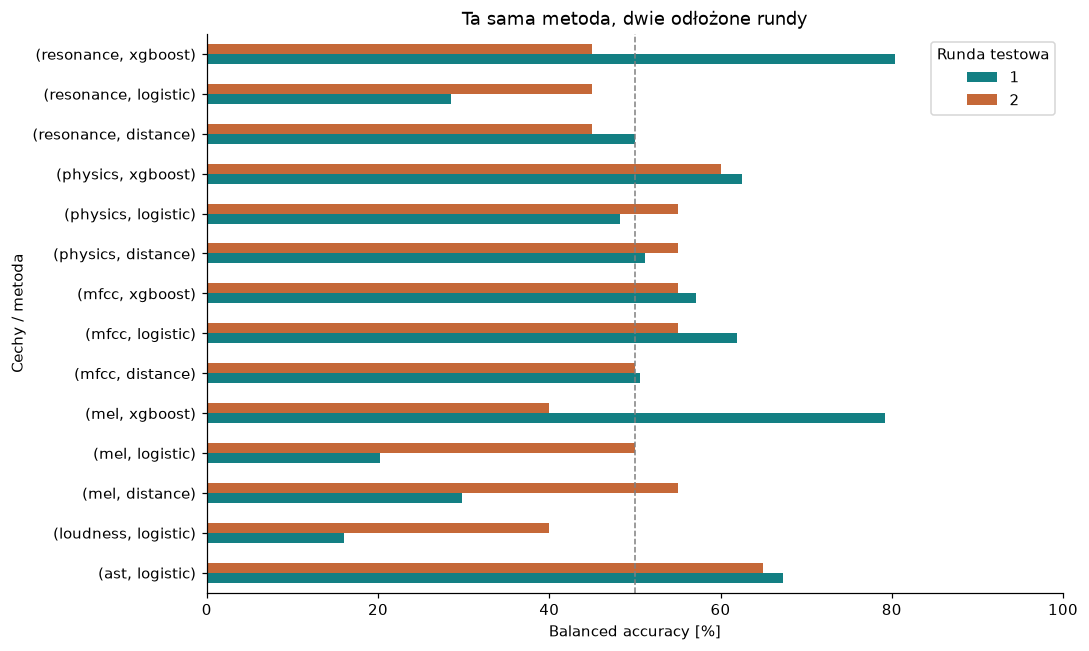

Porównanie gotowe. Oceniaj obie klasy i obie rundy, nie tylko najlepszy pojedynczy wynik.


In [6]:
from compare_xgboost import compare
from sklearn.metrics import accuracy_score

comparison_new = compare(events, OUT/'model_comparison')
# Zachowujemy także detektory odległości oraz AST z wcześniejszych sekcji.
comparison_old = metrics.copy()
round_by_id = events.set_index('event_id')['round']
comparison_old['accuracy'] = [
    accuracy_score(p.label, p.prediction)
    for row in comparison_old.itertuples()
    for p in [predictions[(predictions.family == row.family) &
                          (predictions.method == row.method) &
                          (predictions.event_id.map(round_by_id) == row.test_round)]]
]
comparison = pd.concat([comparison_old, comparison_new.query("method == 'xgboost'")], ignore_index=True)
measures = ['accuracy', 'balanced_accuracy', 'central_recall', 'offcenter_recall', 'auc']
names = {'accuracy':'Accuracy', 'balanced_accuracy':'BA', 'central_recall':'Recall central',
         'offcenter_recall':'Recall off-center', 'auc':'AUC'}
summary = comparison.groupby(['family','method'],sort=True)[measures].mean()
display(Markdown('**Średnia dwóch rund — procenty**'))
display((100*summary).rename(columns=names).round(1))
display(Markdown('**Każda runda osobno — procenty**'))
detail = comparison.set_index(['family','method','test_round'])[measures].sort_index()
display((100*detail).rename(columns=names).round(1))
display(Markdown('**Kontrola przeuczenia XGBoost — BA na treningu i teście**'))
display((100*comparison_new.query("method == 'xgboost'").set_index(['family','test_round'])[
    ['train_ba','balanced_accuracy']]).rename(columns={'train_ba':'Trening BA','balanced_accuracy':'Test BA'}).round(1))
chart = comparison.pivot(index=['family','method'], columns='test_round', values='balanced_accuracy')
ax=(100*chart).plot.barh(figsize=(10, max(5,len(chart)*.43)),color=['#137f83','#c56838'])
ax.axvline(50,color='grey',ls='--',lw=1)
ax.set(xlabel='Balanced accuracy [%]',ylabel='Cechy / metoda',xlim=(0,100),title='Ta sama metoda, dwie odłożone rundy')
ax.legend(title='Runda testowa');plt.tight_layout();plt.show()
comparison.to_csv(OUT/'model_comparison'/'all_models.csv',index=False)
summary.to_csv(OUT/'model_comparison'/'summary.csv')
print('Porównanie gotowe. Oceniaj obie klasy i obie rundy, nie tylko najlepszy pojedynczy wynik.')


In [7]:
print('GOTOWE:', NOTEBOOK, '| pliki wynikowe:', OUT)

GOTOWE: 06_porownanie_metod | pliki wynikowe: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/badminton-notebooks/06_porownanie_metod/20260928_144916_868439
